In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# uplift_train небольшой — загружаем полностью
uplift = pd.read_csv("uplift_train.csv")

# purchases сначала читаем только небольшой фрагмент
purchases_sample = pd.read_csv(
    "purchases.csv",
    nrows=100_000
)

print("Uplift shape:", uplift.shape)
print("Purchases sample shape:", purchases_sample.shape)

display(uplift.head())
display(purchases_sample.head())

Uplift shape: (200039, 3)
Purchases sample shape: (100000, 13)


,client_id,treatment_flg,target
0,000012768d,0,1
1,000036f903,1,1
2,00010925a5,1,1
3,0001f552b0,1,1
4,00020e7b18,1,1


,client_id,transaction_id,transaction_datetime,regular_points_received,express_points_received,regular_points_spent,express_points_spent,purchase_sum,store_id,product_id,product_quantity,trn_sum_from_iss,trn_sum_from_red
0,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,9a80204f78,2.0,80.0,NaN
1,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,da89ebd374,1.0,65.0,NaN
2,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,0a95e1151d,1.0,24.0,NaN
3,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,4055b15e4a,2.0,50.0,NaN
4,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,a685f1916b,1.0,22.0,NaN


In [2]:
print(uplift.info())
print(purchases_sample.info())

<class 'pandas.DataFrame'>
RangeIndex: 200039 entries, 0 to 200038
Data columns (total 3 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   client_id      200039 non-null  str  
 1   treatment_flg  200039 non-null  int64
 2   target         200039 non-null  int64
dtypes: int64(2), str(1)
memory usage: 4.6 MB
None
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   client_id                100000 non-null  str    
 1   transaction_id           100000 non-null  str    
 2   transaction_datetime     100000 non-null  str    
 3   regular_points_received  100000 non-null  float64
 4   express_points_received  100000 non-null  float64
 5   regular_points_spent     100000 non-null  float64
 6   express_points_spent     100000 non-null  float64
 7   purchase_sum             100000 non-

In [3]:
print(purchases_sample.columns.tolist())
print(uplift.columns.tolist())

['client_id', 'transaction_id', 'transaction_datetime', 'regular_points_received', 'express_points_received', 'regular_points_spent', 'express_points_spent', 'purchase_sum', 'store_id', 'product_id', 'product_quantity', 'trn_sum_from_iss', 'trn_sum_from_red']
['client_id', 'treatment_flg', 'target']


In [4]:
purchases_sample["transaction_datetime"] = pd.to_datetime(
    purchases_sample["transaction_datetime"]
)

print(purchases_sample["transaction_datetime"].min())
print(purchases_sample["transaction_datetime"].max())

2018-11-22 05:11:46
2019-03-18 19:36:11


In [5]:
print(uplift["treatment_flg"].value_counts())
print(uplift["target"].value_counts())

print(
    pd.crosstab(
        uplift["treatment_flg"],
        uplift["target"],
        margins=True
    )
)

treatment_flg
0    100058
1     99981
Name: count, dtype: int64
target
1    124002
0     76037
Name: count, dtype: int64
target             0       1     All
treatment_flg                       
0              39695   60363  100058
1              36342   63639   99981
All            76037  124002  200039


In [6]:
sample_transaction = (
    purchases_sample["transaction_id"]
    .value_counts()
    .index[0]
)

purchases_sample[
    purchases_sample["transaction_id"] == sample_transaction
][[
    "client_id",
    "transaction_id",
    "transaction_datetime",
    "product_id",
    "purchase_sum"
]]

,client_id,transaction_id,transaction_datetime,product_id,purchase_sum
12831,000c94c607,543c8a7e4d,2019-03-01 16:46:12,e5a7ffef11,4461.0
12832,000c94c607,543c8a7e4d,2019-03-01 16:46:12,12df549eca,4461.0
12833,000c94c607,543c8a7e4d,2019-03-01 16:46:12,3959267f3b,4461.0
12834,000c94c607,543c8a7e4d,2019-03-01 16:46:12,cc9630a549,4461.0
12835,000c94c607,543c8a7e4d,2019-03-01 16:46:12,90a57517c6,4461.0
12836,000c94c607,543c8a7e4d,2019-03-01 16:46:12,ac9b4aaf02,4461.0
12837,000c94c607,543c8a7e4d,2019-03-01 16:46:12,2080d1ce9d,4461.0
12838,000c94c607,543c8a7e4d,2019-03-01 16:46:12,050135fd94,4461.0
12839,000c94c607,543c8a7e4d,2019-03-01 16:46:12,5e07a35727,4461.0
12840,000c94c607,543c8a7e4d,2019-03-01 16:46:12,eb49aa4218,4461.0


In [7]:
purchase_sum_check = (
    purchases_sample
    .groupby("transaction_id")["purchase_sum"]
    .nunique()
)

print("Транзакций в sample:", len(purchase_sum_check))
print(
    "Транзакций с несколькими значениями purchase_sum:",
    (purchase_sum_check > 1).sum()
)
print("Максимальное число разных purchase_sum:",
      purchase_sum_check.max())

Транзакций в sample: 17292
Транзакций с несколькими значениями purchase_sum: 0
Максимальное число разных purchase_sum: 1


In [9]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("datasets")

usecols = [
    "client_id",
    "transaction_id",
    "transaction_datetime",
    "purchase_sum"
]

# Нас интересуют только клиенты из uplift_train
train_clients = set(uplift["client_id"])

transaction_parts = []

for chunk in pd.read_csv(
    "purchases.csv",
    usecols=usecols,
    chunksize=2_000_000,
    parse_dates=["transaction_datetime"]
):
    # оставляем только клиентов эксперимента
    chunk = chunk[
        chunk["client_id"].isin(train_clients)
    ]

    # одна строка на один чек
    chunk_transactions = (
        chunk
        .drop_duplicates(
            subset=["client_id", "transaction_id"]
        )
    )

    transaction_parts.append(chunk_transactions)

    print("Обработан очередной chunk")

Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk
Обработан очередной chunk


In [10]:
transactions = pd.concat(
    transaction_parts,
    ignore_index=True
)

# На случай, если одна транзакция попала на границу двух chunks
transactions = (
    transactions
    .drop_duplicates(
        subset=["client_id", "transaction_id"]
    )
)

print(transactions.shape)
display(transactions.head())

(4024949, 4)


,client_id,transaction_id,transaction_datetime,purchase_sum
0,000012768d,7e3e2e3984,2018-12-01 07:12:45,1007.0
1,000012768d,c1ca85d462,2018-12-16 08:56:01,574.0
2,000012768d,6a0e96d0bc,2019-03-08 10:12:03,803.0
3,000012768d,b34f23306e,2019-03-14 15:01:47,419.0
4,000036f903,12b218b054,2018-11-28 10:48:36,241.0


In [11]:
print(
    "Минимальная дата:",
    transactions["transaction_datetime"].min()
)

print(
    "Максимальная дата:",
    transactions["transaction_datetime"].max()
)

print(
    "Уникальных клиентов:",
    transactions["client_id"].nunique()
)

print(
    "Уникальных транзакций:",
    transactions["transaction_id"].nunique()
)

Минимальная дата: 2018-11-21 21:02:33
Максимальная дата: 2019-03-18 23:19:28
Уникальных клиентов: 200039
Уникальных транзакций: 4024941


In [12]:
cutoff_date = (
    transactions["transaction_datetime"]
    .max()
    .normalize()
    + pd.Timedelta(days=1)
)

rfm = (
    transactions
    .groupby("client_id")
    .agg(
        last_purchase=(
            "transaction_datetime",
            "max"
        ),
        frequency=(
            "transaction_id",
            "nunique"
        ),
        monetary=(
            "purchase_sum",
            "sum"
        )
    )
    .reset_index()
)

rfm["recency"] = (
    cutoff_date
    - rfm["last_purchase"].dt.normalize()
).dt.days

rfm = rfm[
    [
        "client_id",
        "recency",
        "frequency",
        "monetary"
    ]
]

display(rfm.head())

,client_id,recency,frequency,monetary
0,000012768d,5,4,2803.00
1,000036f903,2,32,9805.00
2,00010925a5,11,18,5883.00
3,0001f552b0,3,15,6155.18
4,00020e7b18,4,18,25819.61


In [13]:
print("Размер RFM:", rfm.shape)
print("Уникальных клиентов:", rfm["client_id"].nunique())

print("\nПропуски:")
print(rfm.isna().sum())

print("\nДубликаты client_id:")
print(rfm["client_id"].duplicated().sum())

print("\nОсновная статистика:")
display(
    rfm[["recency", "frequency", "monetary"]]
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
    )
    .T
)

Размер RFM: (200039, 4)
Уникальных клиентов: 200039

Пропуски:
client_id    0
recency      0
frequency    0
monetary     0
dtype: int64

Дубликаты client_id:
0

Основная статистика:


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
recency,200039.0,6.828868,5.668016,1.00,1.0000,1.000,2.000,5.00,10.000,19.000,22.0000,23.00
frequency,200039.0,20.120821,17.732130,1.00,1.0000,3.000,8.000,15.00,27.000,54.000,85.0000,320.00
monetary,200039.0,8597.521955,8914.597077,1.04,297.0038,951.226,3147.615,6102.44,11094.185,24235.254,41865.7384,504490.38


In [14]:
print("Recency <= 0:", (rfm["recency"] <= 0).sum())
print("Frequency <= 0:", (rfm["frequency"] <= 0).sum())
print("Monetary <= 0:", (rfm["monetary"] <= 0).sum())

Recency <= 0: 0
Frequency <= 0: 0
Monetary <= 0: 0


In [15]:
check = uplift.merge(
    rfm,
    on="client_id",
    how="left",
    indicator=True
)

print(check["_merge"].value_counts())

print(
    "Клиентов uplift без истории покупок:",
    check["recency"].isna().sum()
)

_merge
both          200039
left_only          0
right_only         0
Name: count, dtype: int64
Клиентов uplift без истории покупок: 0


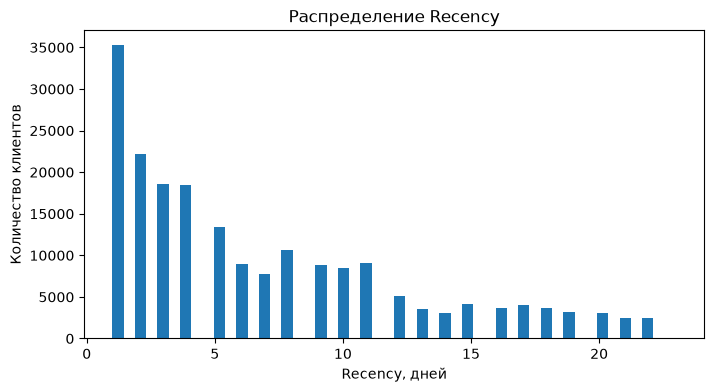

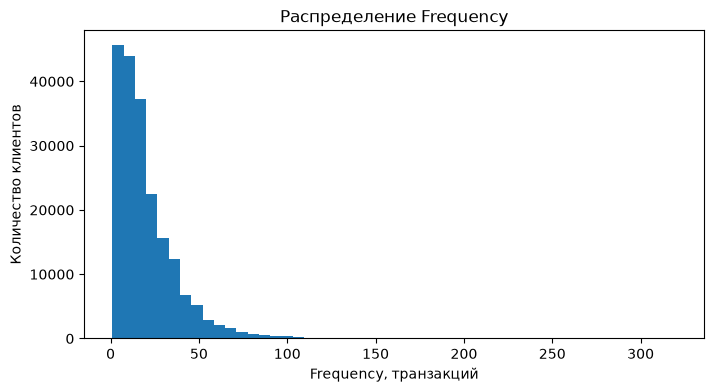

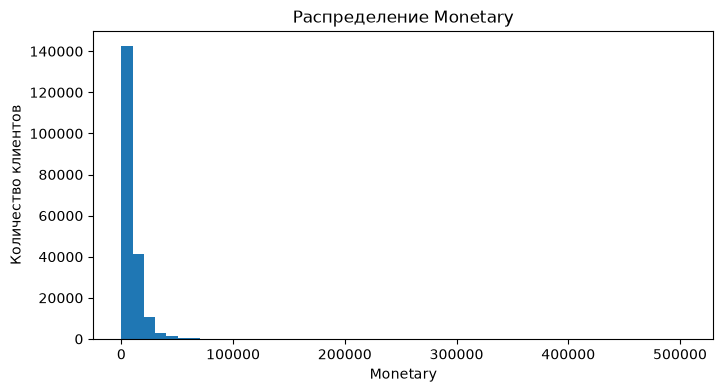

In [16]:
plt.figure(figsize=(8, 4))
plt.hist(rfm["recency"], bins=50)
plt.xlabel("Recency, дней")
plt.ylabel("Количество клиентов")
plt.title("Распределение Recency")
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(rfm["frequency"], bins=50)
plt.xlabel("Frequency, транзакций")
plt.ylabel("Количество клиентов")
plt.title("Распределение Frequency")
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(rfm["monetary"], bins=50)
plt.xlabel("Monetary")
plt.ylabel("Количество клиентов")
plt.title("Распределение Monetary")
plt.show()

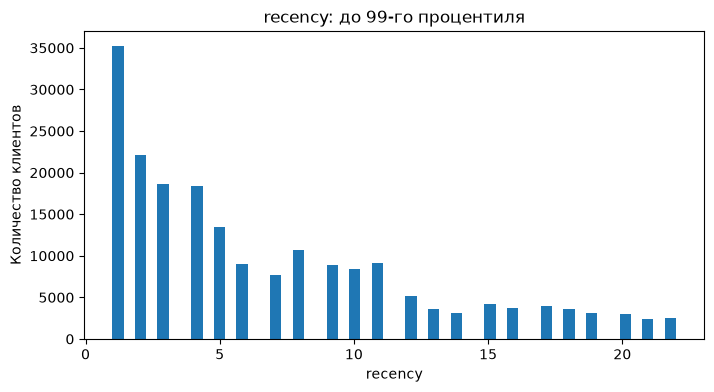

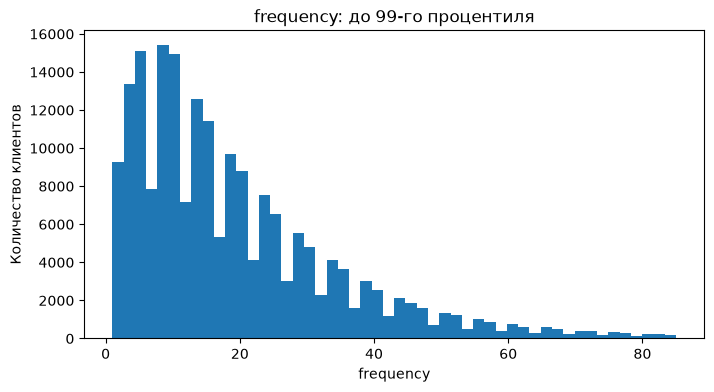

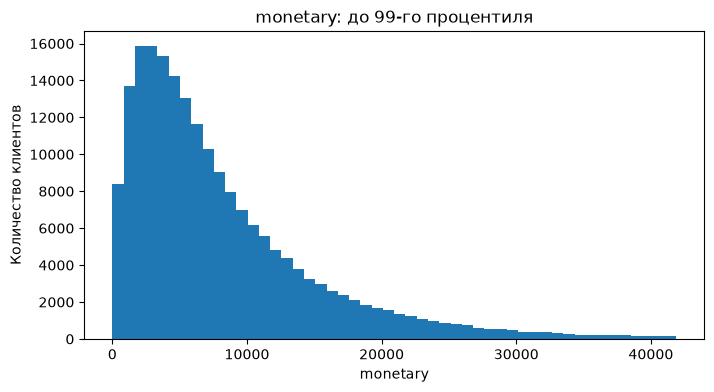

In [17]:
for column in ["recency", "frequency", "monetary"]:
    limit = rfm[column].quantile(0.99)

    plt.figure(figsize=(8, 4))
    plt.hist(
        rfm.loc[rfm[column] <= limit, column],
        bins=50
    )
    plt.xlabel(column)
    plt.ylabel("Количество клиентов")
    plt.title(f"{column}: до 99-го процентиля")
    plt.show()

In [18]:
print(
    rfm[["recency", "frequency", "monetary"]]
    .corr(method="spearman")
)

            recency  frequency  monetary
recency    1.000000  -0.510745 -0.401199
frequency -0.510745   1.000000  0.755083
monetary  -0.401199   0.755083  1.000000


In [19]:
quantiles = rfm[
    ["recency", "frequency", "monetary"]
].quantile([0.2, 0.4, 0.6, 0.8])

display(quantiles)

print("Recency:")
print(rfm["recency"].value_counts().sort_index())

print("\nКвантили:")
print(quantiles)

,recency,frequency,monetary
0.2,2.0,7.0,2621.608
0.4,4.0,12.0,4809.032
0.6,7.0,19.0,7672.224
0.8,11.0,30.0,12764.060


Recency:
recency
1     35273
2     22178
3     18614
4     18406
5     13442
6      8960
7      7697
8     10699
9      8883
10     8419
11     9084
12     5111
13     3575
14     3101
15     4184
16     3718
17     3974
18     3628
19     3151
20     3019
21     2444
22     2478
23        1
Name: count, dtype: int64

Квантили:
     recency  frequency   monetary
0.2      2.0        7.0   2621.608
0.4      4.0       12.0   4809.032
0.6      7.0       19.0   7672.224
0.8     11.0       30.0  12764.060


In [20]:
tx_clients = (
    transactions
    .groupby("transaction_id")["client_id"]
    .nunique()
)

display(
    tx_clients[tx_clients > 1]
    .sort_values(ascending=False)
)

transaction_id
329d79a1cd    2
7e59a6fdab    2
9e8e780945    2
ab91c3ecdc    2
ab93618f46    2
b29f0599cd    2
e6a59bb8dd    2
fdda0ad81b    2
Name: client_id, dtype: int64

In [21]:
def r_score(x):
    if x <= 2:
        return 5
    elif x <= 4:
        return 4
    elif x <= 7:
        return 3
    elif x <= 11:
        return 2
    else:
        return 1

def f_score(x):
    if x <= 7:
        return 1
    elif x <= 12:
        return 2
    elif x <= 19:
        return 3
    elif x <= 30:
        return 4
    else:
        return 5

def m_score(x):
    if x <= 2621.608:
        return 1
    elif x <= 4809.032:
        return 2
    elif x <= 7672.224:
        return 3
    elif x <= 12764.060:
        return 4
    else:
        return 5

rfm["R_score"] = rfm["recency"].apply(r_score)
rfm["F_score"] = rfm["frequency"].apply(f_score)
rfm["M_score"] = rfm["monetary"].apply(m_score)

rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)

display(rfm.head())

print("R-score:")
print(rfm["R_score"].value_counts().sort_index())

print("\nF-score:")
print(rfm["F_score"].value_counts().sort_index())

print("\nM-score:")
print(rfm["M_score"].value_counts().sort_index())

print("\nСамые частые RFM-комбинации:")
print(rfm["RFM_score"].value_counts().head(20))

,client_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score
0,000012768d,5,4,2803.00,3,1,2,312
1,000036f903,2,32,9805.00,5,5,4,554
2,00010925a5,11,18,5883.00,2,3,3,233
3,0001f552b0,3,15,6155.18,4,3,3,433
4,00020e7b18,4,18,25819.61,4,3,5,435


R-score:
R_score
1    38384
2    37085
3    30099
4    37020
5    57451
Name: count, dtype: int64

F-score:
F_score
1    45633
2    37531
3    39057
4    38085
5    39733
Name: count, dtype: int64

M-score:
M_score
1    40008
2    40008
3    40007
4    40008
5    40008
Name: count, dtype: int64

Самые частые RFM-комбинации:
RFM_score
555    13315
111    11575
211     9440
554     6719
544     4726
455     4488
545     4192
112     3902
122     3773
311     3540
543     3533
212     3213
222     3053
533     3014
444     2990
445     2931
454     2663
411     2584
553     2539
534     2535
Name: count, dtype: int64


In [22]:
rfm["RFM_total"] = (
    rfm["R_score"]
    + rfm["F_score"]
    + rfm["M_score"]
)

print(rfm["RFM_total"].value_counts().sort_index())

print(
    "\nКвантили RFM_total:"
)

print(
    rfm["RFM_total"].quantile(
        [0, 0.2, 0.4, 0.6, 0.8, 1]
    )
)

RFM_total
3     11575
4     15698
5     14019
6     14671
7     15986
8     16183
9     16405
10    16861
11    16812
12    16823
13    16292
14    15399
15    13315
Name: count, dtype: int64

Квантили RFM_total:
0.0     3.0
0.2     5.0
0.4     8.0
0.6    10.0
0.8    13.0
1.0    15.0
Name: RFM_total, dtype: float64


In [23]:
def assign_segment(score):
    if score <= 5:
        return "Низкая ценность"
    elif score <= 8:
        return "Ниже средней"
    elif score <= 10:
        return "Средняя"
    elif score <= 13:
        return "Выше средней"
    else:
        return "Высокая ценность"

rfm["rfm_segment"] = rfm["RFM_total"].apply(assign_segment)

print(rfm["rfm_segment"].value_counts())

segment_order = [
    "Низкая ценность",
    "Ниже средней",
    "Средняя",
    "Выше средней",
    "Высокая ценность"
]

rfm["rfm_segment"] = pd.Categorical(
    rfm["rfm_segment"],
    categories=segment_order,
    ordered=True
)

data = rfm.merge(
    uplift,
    on="client_id",
    how="inner"
)

print(data.shape)
display(data.head())

rfm_segment
Выше средней        49927
Ниже средней        46840
Низкая ценность     41292
Средняя             33266
Высокая ценность    28714
Name: count, dtype: int64
(200039, 12)


,client_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,RFM_total,rfm_segment,treatment_flg,target
0,000012768d,5,4,2803.00,3,1,2,312,6,Ниже средней,0,1
1,000036f903,2,32,9805.00,5,5,4,554,14,Высокая ценность,1,1
2,00010925a5,11,18,5883.00,2,3,3,233,8,Ниже средней,1,1
3,0001f552b0,3,15,6155.18,4,3,3,433,10,Средняя,1,1
4,00020e7b18,4,18,25819.61,4,3,5,435,12,Выше средней,1,1


In [24]:
segment_groups = pd.crosstab(
    data["rfm_segment"],
    data["treatment_flg"]
)

segment_groups.columns = ["Control", "Treatment"]

display(segment_groups)

,Control,Treatment
rfm_segment,,
Низкая ценность,20693,20599
Ниже средней,23575,23265
Средняя,16620,16646
Выше средней,24824,25103
Высокая ценность,14346,14368


In [25]:
segment_results = (
    data
    .groupby(
        ["rfm_segment", "treatment_flg"],
        observed=True
    )
    .agg(
        n=("target", "size"),
        conversions=("target", "sum"),
        conversion_rate=("target", "mean")
    )
    .reset_index()
)

display(segment_results)

,rfm_segment,treatment_flg,n,conversions,conversion_rate
0,Низкая ценность,0,20693,6174,0.298362
1,Низкая ценность,1,20599,7097,0.344531
2,Ниже средней,0,23575,11410,0.483987
3,Ниже средней,1,23265,12247,0.526413
4,Средняя,0,16620,10378,0.624428
5,Средняя,1,16646,11052,0.663943
6,Выше средней,0,24824,19239,0.775016
7,Выше средней,1,25103,19934,0.794088
8,Высокая ценность,0,14346,13162,0.917468
9,Высокая ценность,1,14368,13309,0.926295


In [30]:
import numpy as np
import pandas as pd

from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)
from statsmodels.stats.multitest import multipletests

results = []

for segment in segment_order:
    subset = data[data["rfm_segment"] == segment]

    control = subset[subset["treatment_flg"] == 0]
    treatment = subset[subset["treatment_flg"] == 1]

    n_c = len(control)
    n_t = len(treatment)

    y_c = control["target"].sum()
    y_t = treatment["target"].sum()

    p_c = y_c / n_c
    p_t = y_t / n_t

    uplift = p_t - p_c

    # 95% CI для разницы долей — Newcombe
    ci_low, ci_high = confint_proportions_2indep(
        count1=y_t,
        nobs1=n_t,
        count2=y_c,
        nobs2=n_c,
        method="newcomb",
        compare="diff"
    )

    # z-test разницы двух долей
    z_stat, p_value = proportions_ztest(
        count=[y_t, y_c],
        nobs=[n_t, n_c]
    )

    results.append({
        "segment": segment,
        "n_control": n_c,
        "n_treatment": n_t,
        "control_rate": p_c,
        "treatment_rate": p_t,
        "uplift": uplift,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

# Поправка Холма на множественные сравнения
results_df["p_holm"] = multipletests(
    results_df["p_value"],
    method="holm"
)[1]

results_df["significant"] = (
    results_df["p_holm"] < 0.05
)

display(results_df)

,segment,n_control,n_treatment,control_rate,treatment_rate,uplift,ci_low,ci_high,p_value,p_holm,significant
0,Низкая ценность,20693,20599,0.298362,0.344531,0.046170,0.037166,0.055163,9.711210e-24,4.855605e-23,True
1,Ниже средней,23575,23265,0.483987,0.526413,0.042426,0.033374,0.051468,4.220091e-20,1.688036e-19,True
2,Средняя,16620,16646,0.624428,0.663943,0.039515,0.029229,0.049789,5.194662e-14,1.558399e-13,True
3,Выше средней,24824,25103,0.775016,0.794088,0.019072,0.011860,0.026283,2.182256e-07,4.364511e-07,True
4,Высокая ценность,14346,14368,0.917468,0.926295,0.008826,0.002618,0.015039,5.325082e-03,5.325082e-03,True


In [31]:
final_table = results_df.copy()

for col in [
    "control_rate",
    "treatment_rate",
    "uplift",
    "ci_low",
    "ci_high"
]:
    final_table[col] *= 100

final_table["95% CI"] = (
    final_table["ci_low"].round(2).astype(str)
    + " – "
    + final_table["ci_high"].round(2).astype(str)
)

final_table = final_table[
    [
        "segment",
        "n_control",
        "n_treatment",
        "control_rate",
        "treatment_rate",
        "uplift",
        "95% CI",
        "p_holm"
    ]
]

display(final_table.round(4))

,segment,n_control,n_treatment,control_rate,treatment_rate,uplift,95% CI,p_holm
0,Низкая ценность,20693,20599,29.8362,34.4531,4.6170,3.72 – 5.52,0.0000
1,Ниже средней,23575,23265,48.3987,52.6413,4.2426,3.34 – 5.15,0.0000
2,Средняя,16620,16646,62.4428,66.3943,3.9515,2.92 – 4.98,0.0000
3,Выше средней,24824,25103,77.5016,79.4088,1.9072,1.19 – 2.63,0.0000
4,Высокая ценность,14346,14368,91.7468,92.6295,0.8826,0.26 – 1.5,0.0053


In [32]:
import statsmodels.formula.api as smf

segment_map = {
    "Низкая ценность": 1,
    "Ниже средней": 2,
    "Средняя": 3,
    "Выше средней": 4,
    "Высокая ценность": 5
}

data["rfm_level"] = (
    data["rfm_segment"]
    .astype(str)
    .map(segment_map)
)

trend_model = smf.ols(
    "target ~ treatment_flg * rfm_level",
    data=data
).fit(cov_type="HC3")

print(trend_model.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.176
Model:                            OLS   Adj. R-squared:                  0.176
Method:                 Least Squares   F-statistic:                 1.702e+04
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:17:53   Log-Likelihood:            -1.1985e+05
No. Observations:              200039   AIC:                         2.397e+05
Df Residuals:                  200035   BIC:                         2.397e+05
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 